

Air Quality and Pollution Assessment

IT326 – Data Mining Project

Final Project Report — Phase 3

This project investigates air quality classification and clustering using data mining techniques. The report presents the dataset, preprocessing methods, classification and clustering algorithms, evaluation results, and final findings.



# 1. Problem

Air pollution is a major environmental concern because pollutant concentrations and surrounding environmental conditions can vary across locations and observations. Understanding these measurements is important for identifying air quality levels and discovering patterns in environmental data.

The problem addressed in this project is to analyze the relationship between environmental measurements and air quality categories. The project uses classification to predict the recorded Air Quality category from numerical environmental features, and clustering to discover groups of observations with similar measurement patterns.

The analysis is based on the supplied Air Quality and Pollution Assessment dataset. The results describe patterns in this dataset and should not be interpreted as real-time air quality forecasts or as proof of causal relationships.

# 2. Data Mining Task

This project includes two data mining tasks:

1. **Classification (supervised learning):** Decision Tree models are trained to predict the Air Quality target. The Gini and Entropy (Information Gain) criteria are evaluated using three stratified train/test partitions: 90/10, 80/20, and 70/30. Accuracy and confusion matrices are used to compare the six model configurations.
2. **Clustering (unsupervised learning):** K-Means is applied to the numerical input features without using Air Quality as a clustering input. The experiments compare K=2, K=3, and K=4 using WCSS (Elbow Method), Silhouette Score, cluster-size distributions, and PCA visualizations.

The objective is to compare the classification configurations, select a suitable number of clusters based on the evaluation evidence, and interpret the patterns represented by the resulting groups.

# 3. Data

The dataset used in this project is the Air Quality and Pollution Assessment dataset, obtained from Kaggle.

Dataset source: https://www.kaggle.com/datasets/mujtabamatin/air-quality-and-pollution-assessment

The dataset contains environmental measurements and air pollution indicators that are used to analyze air quality. It includes nine input features describing environmental conditions and pollutant concentrations, along with one target attribute representing the air quality category.

The dataset is used to study air quality classification, where environmental features are used to predict the corresponding air quality class.

In [ ]:
import pandas as pd

df = pd.read_csv("Raw_dataset.csv")

print("Dataset Description")
print("-------------------")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nFeature Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes.to_frame(name="Data Type"))

Dataset Description
-------------------
Number of rows: 5000
Number of columns: 10

Feature Names:
['Temperature', 'Humidity', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'Proximity_to_Industrial_Areas', 'Population_Density', 'Air Quality']

Data Types:


,Data Type
Temperature,float64
Humidity,float64
PM2.5,float64
PM10,float64
NO2,float64
SO2,float64
CO,float64
Proximity_to_Industrial_Areas,float64
Population_Density,int64
Air Quality,object


In [ ]:
print("Dataset Preview:")
display(df.head())

Dataset Preview:


,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality
0,29.8,59.1,5.2,17.9,18.9,9.2,1.72,6.3,319,Moderate
1,28.3,75.6,2.3,12.2,30.8,9.7,1.64,6.0,611,Moderate
2,23.1,74.7,26.7,33.8,24.4,12.6,1.63,5.2,619,Moderate
3,27.1,39.1,6.1,6.3,13.5,5.3,1.15,11.1,551,Good
4,26.5,70.7,6.9,16.0,21.9,5.6,1.01,12.7,303,Good




The first five rows provide an overview of the dataset structure, showing the environmental measurements and their corresponding air quality categories. This preview helps verify the column names and the format of the observations before further analysis.

In [ ]:
class_label = "Air Quality"

print("Class Label:", class_label)

class_distribution = df[class_label].value_counts().to_frame(
    name="Number of Instances"
)

class_distribution["Percentage (%)"] = (
    df[class_label].value_counts(normalize=True) * 100
).round(2)

display(class_distribution)

Class Label: Air Quality


,Number of Instances,Percentage (%)
Air Quality,,
Good,2000,40.0
Moderate,1500,30.0
Poor,1000,20.0
Hazardous,500,10.0


The class distribution shows that Good is the most frequent category, whereas Hazardous is the least frequent. Examining the number and percentage of instances in each class helps identify the distribution of the target variable and determine whether the classes are balanced or imbalanced.

# 4. Data Preprocessing


Introduction

Data preprocessing is an important step in data mining because it helps prepare raw data for analysis and modeling. The quality and format of the input data can affect the performance and reliability of machine learning algorithms.

In this project, preprocessing techniques are used to prepare the air quality dataset for classification and clustering. The selected techniques aim to transform numerical features, standardize their ranges, and organize selected values into meaningful categories.

This section describes the preprocessing techniques applied in the project, explains the reasons for selecting them, and discusses the changes observed in the dataset before and after preprocessing.

### 4.1 Variable Transformation

Variable transformation was performed to examine the distributions of the numerical attributes in the Air Quality dataset.

The skewness of the numerical attributes was calculated to identify features with asymmetric distributions. The results showed that PM2.5, PM10, and SO2 had relatively high positive skewness.

These attributes had the following initial skewness values:

| Attribute | Skewness |
|:---|---:|
| PM2.5 | 2.890910 |
| PM10 | 2.534815 |
| SO2 | 1.166772 |

The positive skewness values indicated that these attributes had asymmetric distributions. Therefore, a logarithmic transformation was applied to these three attributes in the next preprocessing step to reduce their skewness.

### 4.2 Log Transformation

Log transformation was applied to PM2.5, PM10, and SO2 using NumPy's log1p() function. The purpose of this transformation was to reduce the positive skewness observed in these attributes.

The transformation is defined as:

$$
x' = \log(1+x)
$$

The skewness values before and after transformation were:

| Attribute | Before Transformation | After Transformation |
|:---|---:|---:|
| PM2.5 | 2.890910 | -0.111306 |
| PM10 | 2.534815 | 0.099418 |
| SO2 | 1.166772 | 0.204137 |

The results show that skewness decreased substantially for all three attributes. PM2.5 became slightly negatively skewed, while PM10 and SO2 became less positively skewed.

Overall, the results indicate that the logarithmic transformation made the distributions of the selected attributes more symmetric.

### 4.3 Normalization

Normalization was performed using the MinMaxScaler() function from Scikit-learn to scale numerical attributes to a common range between 0 and 1.

The Min-Max normalization formula is:

$$
X' = \frac{X-X_{\min}}{X_{\max}-X_{\min}}
$$

This technique transforms numerical values to a common scale while preserving their relative positions within each attribute.

After normalization, the numerical attributes had minimum values of 0 and maximum values of 1. This confirms that the features were scaled to the intended range.

Normalization is useful because numerical attributes may originally have different ranges. Scaling them to a common range can help prevent features with larger numerical values from dominating distance-based calculations.

The normalized dataset was saved as Preprocessed_dataset.csv for subsequent analysis.

### 4.4 Discretization

Discretization was applied to the Temperature attribute to convert continuous numerical values into discrete categories.

The KBinsDiscretizer() function from Scikit-learn was used to divide the Temperature values into three bins. The uniform strategy was selected to create bins with equal widths, and ordinal encoding was used to represent the bins with numerical labels.

The distribution of records across the three bins was:

| Temperature Bin | Number of Records |
|:---|---:|
| 0 | 2,337 |
| 1 | 2,456 |
| 2 | 207 |
| Total | 5,000 |

The results show that most records belonged to bins 0 and 1, while fewer records belonged to bin 2.

Discretization simplifies the representation of a continuous attribute by grouping its values into categories.

Note: The discretized values were stored in a separate DataFrame named discretized_df. However, the final dataset was created from normalized_df, so the discretized Temperature values were not retained in the exported dataset.

### 4.5 Feature Selection

Feature selection was performed to reduce the number of input attributes while retaining features that showed a relatively strong relationship with the target variable, Air Quality.

First, the Air Quality categories were converted into numerical values:

- Good = 0
- Moderate = 1
- Poor = 2
- Hazardous = 3

Next, the absolute correlation between each numerical feature and the encoded Air Quality target was calculated. A threshold of 0.5 was used to select the features.

The correlation results were:

| Feature | Absolute Correlation |
|:---|---:|
| CO | 0.912534 |
| NO2 | 0.785030 |
| Proximity_to_Industrial_Areas | 0.773637 |
| SO2 | 0.723187 |
| Temperature | 0.670836 |
| Population_Density | 0.645546 |
| Humidity | 0.625546 |
| PM10 | 0.613076 |
| PM2.5 | 0.402963 |

Eight features met the correlation threshold of 0.5 and were selected: CO, NO2, Proximity_to_Industrial_Areas, SO2, Temperature, Population_Density, Humidity, and PM10.

PM2.5 was excluded because its absolute correlation value of 0.402963 was below the selected threshold.

Feature selection reduced the number of input features while retaining the target variable, Air Quality, for subsequent analysis.

The Temperature value (0.6708) was computed on the discretized Temperature attribute used at that step; the correlation of the continuous Temperature with the target is 0.7536. Both values are above the 0.5 threshold, so the selection result is the same.

It is important to note that correlation indicates an association between variables; it does not establish causation or guarantee improved model performance.

### 4.6 Raw vs. Preprocessed Dataset

The raw and preprocessed datasets were compared to evaluate the changes resulting from the preprocessing process.

The original dataset contained 5,000 rows and 10 columns, while the final preprocessed dataset contained 5,000 rows and 9 columns.

The comparison is summarized below:

| Property | Raw Dataset | Final Preprocessed Dataset |
|:---|---:|---:|
| Number of Rows | 5,000 | 5,000 |
| Number of Columns | 10 | 9 |
| PM2.5 Feature | Included | Excluded |
| Numerical Feature Scaling | Original Scale | Scaled to [0, 1] |
| Target Variable | Air Quality | Air Quality Retained |

The dataset retained all 5,000 records after preprocessing. However, the number of columns decreased from 10 to 9 because PM2.5 was excluded during feature selection.

The numerical features in the final dataset were scaled to a range between 0 and 1. This helps make the numerical attributes more comparable during subsequent analysis.

Although discretization was applied to Temperature in a separate DataFrame, the final dataset was created from normalized_df. Therefore, the discretized Temperature values were not retained in the exported dataset.

Overall, the preprocessing process transformed the numerical features, reduced the skewness of selected attributes, normalized their scales, and reduced the number of input features while retaining all observations and the Air Quality target variable.

# 5. Data Mining Technique

## 5.1 K-Means Clustering

# K-Means Preprocessing (Scale Data)

In [ ]:
from pathlib import Path

import pandas as pd

df = pd.read_csv("Preprocessed_dataset.csv" if Path("Preprocessed_dataset.csv").exists() else "Final_Preprocessed_Dataset.csv")

print(df.info())

# K-Means Preprocessing (Scale Data)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
import numpy as np

# Select numerical columns automatically
df_cluster = df.select_dtypes(include=['number']).copy()

# Handle missing values
df_cluster = df_cluster.fillna(df_cluster.mean())

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster)

print("Data scaled successfully!")
print("Shape:", X_scaled.shape)
print("Features used:", df_cluster.columns.tolist())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   CO                             5000 non-null   float64
 1   NO2                            5000 non-null   float64
 2   Proximity_to_Industrial_Areas  5000 non-null   float64
 3   Temperature                    5000 non-null   float64
 4   SO2                            5000 non-null   float64
 5   Population_Density             5000 non-null   float64
 6   Humidity                       5000 non-null   float64
 7   PM10                           5000 non-null   float64
 8   Air Quality                    5000 non-null   object 
dtypes: float64(8), object(1)
memory usage: 351.7+ KB
None
Data scaled successfully!
Shape: (5000, 8)
Features used: ['CO', 'NO2', 'Proximity_to_Industrial_Areas', 'Temperature', 'SO2', 'Population_Density', 'Humidity', 'PM10']


This cell prepares the numerical features for K-Means clustering by handling missing values and applying StandardScaler. The Air Quality target column is excluded because K-Means is an unsupervised learning algorithm.

# Elbow Method (WCSS) for K Selection

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   CO                             5000 non-null   float64
 1   NO2                            5000 non-null   float64
 2   Proximity_to_Industrial_Areas  5000 non-null   float64
 3   Temperature                    5000 non-null   float64
 4   SO2                            5000 non-null   float64
 5   Population_Density             5000 non-null   float64
 6   Humidity                       5000 non-null   float64
 7   PM10                           5000 non-null   float64
 8   Air Quality                    5000 non-null   object 
dtypes: float64(8), object(1)
memory usage: 351.7+ KB
None


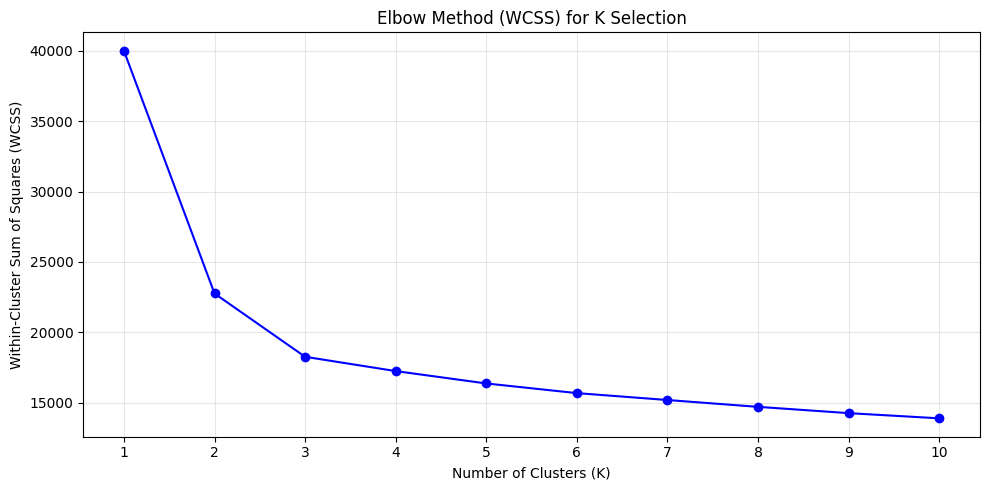


📉 WCSS values:
K=1: WCSS=40000.00
K=2: WCSS=22756.56
K=3: WCSS=18261.36
K=4: WCSS=17245.61
K=5: WCSS=16367.16
K=6: WCSS=15680.71
K=7: WCSS=15191.38
K=8: WCSS=14705.06
K=9: WCSS=14258.73
K=10: WCSS=13889.44

💡 Suggested K values: 2, 3, or 4 (compare the elbow)


In [ ]:
from pathlib import Path
import pandas as pd

df = pd.read_csv("Preprocessed_dataset.csv" if Path("Preprocessed_dataset.csv").exists() else "Final_Preprocessed_Dataset.csv")

print(df.info())


# Elbow Method (WCSS) for K Selection

wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(10, 5))
plt.plot(K_range, wcss, marker='o', color='blue')

plt.title('Elbow Method (WCSS) for K Selection')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.xticks(K_range)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print WCSS values
print("\n📉 WCSS values:")

for k, value in zip(K_range, wcss):
    print(f"K={k}: WCSS={value:.2f}")

# Suggest K values for further experiments
print("\n💡 Suggested K values: 2, 3, or 4 (compare the elbow)")



This cell implements the Elbow Method by calculating WCSS for K=1 to 10 using the air quality dataset. The “elbow point,” where WCSS decreases more slowly, helps identify a suitable number of clusters. Based on the plot, we will test three different K values (2, 3, and 4) for comparison.

# Run K-Means with Three Different K Values

In [ ]:
from pathlib import Path
import pandas as pd

df = pd.read_csv("Preprocessed_dataset.csv" if Path("Preprocessed_dataset.csv").exists() else "Final_Preprocessed_Dataset.csv")

print(df.info())


# Choose three K values for comparison
K_values = [2, 3, 4]

kmeans_models = {}
cluster_labels = {}
kmeans_results = []

print("\n" + "=" * 60)
print("K-MEANS CLUSTERING WITH DIFFERENT K VALUES")
print("=" * 60)

for k in K_values:
    print(f"\n🔵 Training K-Means with K={k}")

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    kmeans_models[k] = kmeans
    cluster_labels[k] = labels

    # Calculate WCSS
    wcss = kmeans.inertia_

    # Calculate Silhouette Score
    sil_score = silhouette_score(X_scaled, labels)

    kmeans_results.append({
        'K': k,
        'WCSS (Inertia)': wcss,
        'Silhouette Score': sil_score
    })

    print(f"   Inertia (WCSS): {wcss:.2f}")
    print(f"   Silhouette Score: {sil_score:.4f}")




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   CO                             5000 non-null   float64
 1   NO2                            5000 non-null   float64
 2   Proximity_to_Industrial_Areas  5000 non-null   float64
 3   Temperature                    5000 non-null   float64
 4   SO2                            5000 non-null   float64
 5   Population_Density             5000 non-null   float64
 6   Humidity                       5000 non-null   float64
 7   PM10                           5000 non-null   float64
 8   Air Quality                    5000 non-null   object 
dtypes: float64(8), object(1)
memory usage: 351.7+ KB
None

K-MEANS CLUSTERING WITH DIFFERENT K VALUES

🔵 Training K-Means with K=2
   Inertia (WCSS): 22756.56
   Silhouette Score: 0.3495

🔵 Training K-Means with K=3
   Inertia (WCSS)

This cell trains K-Means on the air quality dataset using three different K values (2, 3, and 4), based on the Elbow Method results. It stores each model and calculates both WCSS and Silhouette Score to evaluate and compare the clustering performance.

# Silhouette Score Comparison & Analysis

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   CO                             5000 non-null   float64
 1   NO2                            5000 non-null   float64
 2   Proximity_to_Industrial_Areas  5000 non-null   float64
 3   Temperature                    5000 non-null   float64
 4   SO2                            5000 non-null   float64
 5   Population_Density             5000 non-null   float64
 6   Humidity                       5000 non-null   float64
 7   PM10                           5000 non-null   float64
 8   Air Quality                    5000 non-null   object 
dtypes: float64(8), object(1)
memory usage: 351.7+ KB
None


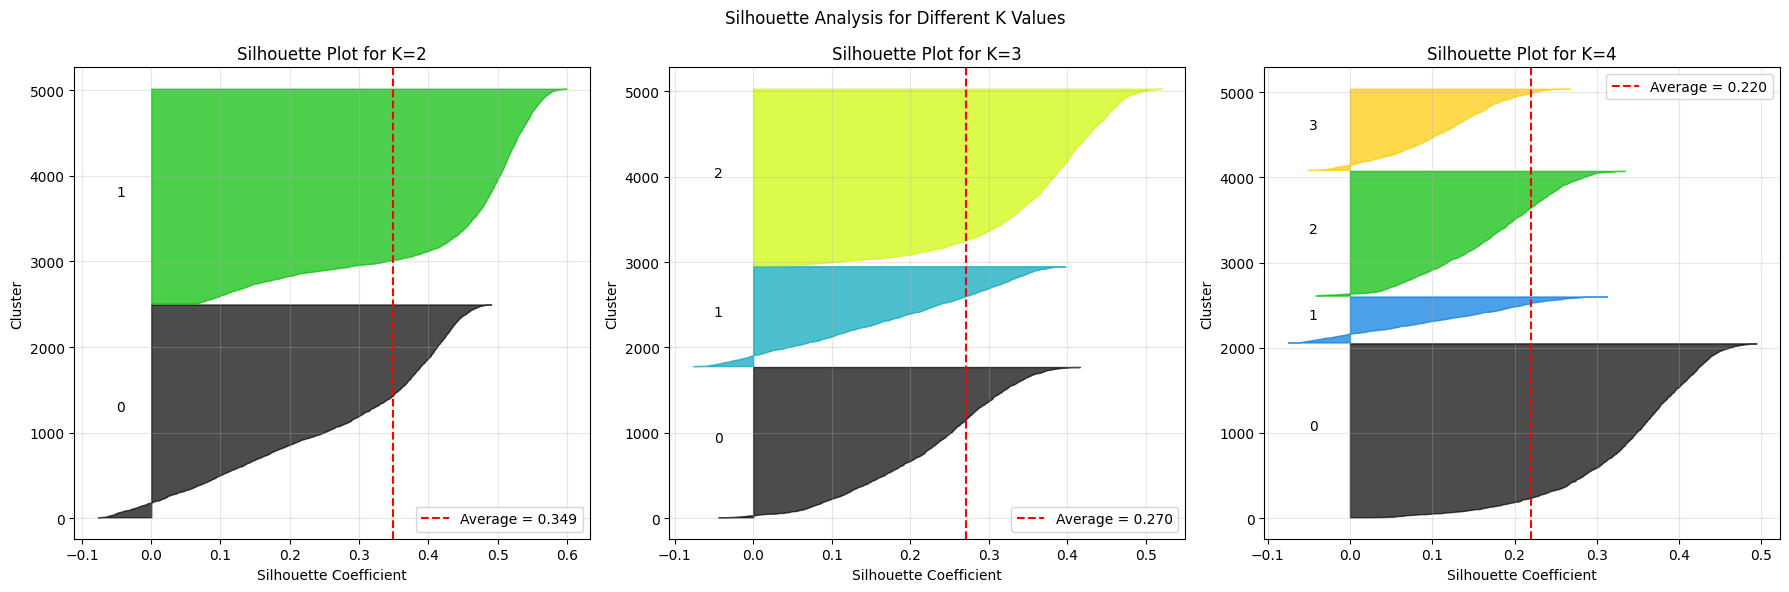


K-MEANS EVALUATION SUMMARY
------------------------------------------------------------
K         WCSS (Inertia)         Silhouette Score    
------------------------------------------------------------
2         22756.56               0.3495              
3         18261.36               0.2705              
4         17245.61               0.2195              
------------------------------------------------------------


In [ ]:
from pathlib import Path
import pandas as pd

df = pd.read_csv("Preprocessed_dataset.csv" if Path("Preprocessed_dataset.csv").exists() else "Final_Preprocessed_Dataset.csv")

print(df.info())


fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, k in enumerate(K_values):
    labels = cluster_labels[k]

    sil_avg = silhouette_score(X_scaled, labels)
    sample_silhouette_values = silhouette_samples(
        X_scaled, labels
    )

    ax = axes[idx]
    y_lower = 10

    for i in range(k):
        cluster_values = sample_silhouette_values[labels == i]
        cluster_values.sort()

        size_cluster = cluster_values.shape[0]
        y_upper = y_lower + size_cluster

        color = cm.nipy_spectral(float(i) / k)

        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            cluster_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7
        )

        ax.text(-0.05, y_lower + 0.5 * size_cluster, str(i))
        y_lower = y_upper + 10

    ax.axvline(
        x=sil_avg,
        color='red',
        linestyle='--',
        label=f'Average = {sil_avg:.3f}'
    )

    ax.set_title(f'Silhouette Plot for K={k}')
    ax.set_xlabel('Silhouette Coefficient')
    ax.set_ylabel('Cluster')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Silhouette Analysis for Different K Values')
plt.tight_layout()
plt.show()



print("\nK-MEANS EVALUATION SUMMARY")
print("-" * 60)

print(
    f"{'K':<10}"
    f"{'WCSS (Inertia)':<23}"
    f"{'Silhouette Score':<20}"
)

print("-" * 60)

for k in [2, 3, 4]:


    wcss = kmeans_models[k].inertia_


    labels = cluster_labels[k]


    silhouette = silhouette_score(X_scaled, labels)


    print(
        f"{k:<10}"
        f"{wcss:<23.2f}"
        f"{silhouette:<20.4f}"
    )

print("-" * 60)



# Visualize Clusters (PCA Projection)

This cell creates silhouette plots for each K value (2, 3, and 4), showing how well-separated the clusters are in the air quality dataset. The red dashed line represents the average Silhouette Score. Higher scores (closer to 1) indicate better-defined clusters. This helps compare clustering quality across different K values.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   CO                             5000 non-null   float64
 1   NO2                            5000 non-null   float64
 2   Proximity_to_Industrial_Areas  5000 non-null   float64
 3   Temperature                    5000 non-null   float64
 4   SO2                            5000 non-null   float64
 5   Population_Density             5000 non-null   float64
 6   Humidity                       5000 non-null   float64
 7   PM10                           5000 non-null   float64
 8   Air Quality                    5000 non-null   object 
dtypes: float64(8), object(1)
memory usage: 351.7+ KB
None


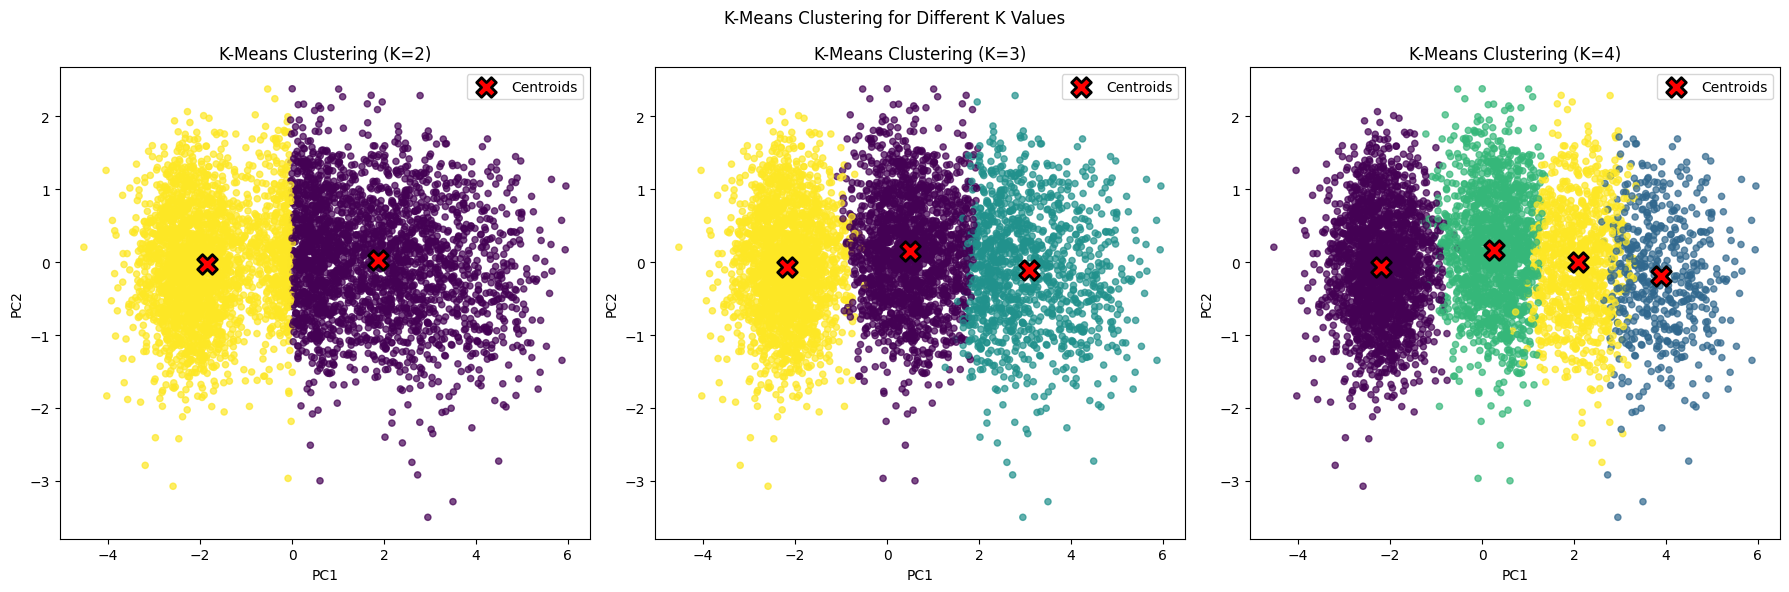


PCA EXPLAINED VARIANCE SUMMARY
--------------------------------------------------
Component                Explained Variance (%)   
--------------------------------------------------
PC1                      59.61%
PC2                      7.70%
--------------------------------------------------
Total                    67.31%
--------------------------------------------------


In [ ]:
from pathlib import Path
import pandas as pd

df = pd.read_csv("Preprocessed_dataset.csv" if Path("Preprocessed_dataset.csv").exists() else "Final_Preprocessed_Dataset.csv")

print(df.info())

# Reduce data to two dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Transform cluster centers to PCA space
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, k in enumerate(K_values):
    labels = cluster_labels[k]
    model = kmeans_models[k]

    centers_pca = pca.transform(model.cluster_centers_)

    axes[idx].scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap='viridis',
        alpha=0.7,
        s=20
    )

    axes[idx].scatter(
        centers_pca[:, 0],
        centers_pca[:, 1],
        s=200,
        c='red',
        marker='X',
        edgecolors='black',
        linewidths=2,
        label='Centroids'
    )

    axes[idx].set_title(f'K-Means Clustering (K={k})')
    axes[idx].set_xlabel('PC1')
    axes[idx].set_ylabel('PC2')
    axes[idx].legend()

plt.suptitle('K-Means Clustering for Different K Values')
plt.tight_layout()
plt.show()



explained_variance = pca.explained_variance_ratio_ * 100

pca_summary = pd.DataFrame({
    'Principal Component': ['PC1', 'PC2'],
    'Explained Variance (%)': explained_variance[:2]
})

print("\nPCA EXPLAINED VARIANCE SUMMARY")
print("-" * 50)
print(f"{'Component':<25}{'Explained Variance (%)':<25}")
print("-" * 50)

for _, row in pca_summary.iterrows():
    print(
        f"{row['Principal Component']:<25}"
        f"{row['Explained Variance (%)']:.2f}%"
    )

print("-" * 50)
print(f"{'Total':<25}{explained_variance[:2].sum():.2f}%")
print("-" * 50)


This cell uses PCA to reduce the numerical features of the air quality dataset to 2D for visualization. Each point is colored according to its cluster assignment, and red ‘X’ markers represent the cluster centroids. This helps visually assess cluster separation and distribution for different K values.

# Clustering Final Conclusion

In [ ]:
from pathlib import Path

import pandas as pd

df = pd.read_csv("Preprocessed_dataset.csv" if Path("Preprocessed_dataset.csv").exists() else "Final_Preprocessed_Dataset.csv")

print(df.info())

# ================================================================
# CLUSTERING (K-MEANS) - FINAL CONCLUSION
# ================================================================

print("=" * 80)
print("CLUSTERING (K-MEANS) - FINAL CONCLUSION")
print("=" * 80)

print("\n OBJECTIVE:")
print("-" * 60)
print("""
To discover natural groupings in the air quality dataset using K-Means clustering with:
• Three different K values (2, 3, and 4) based on the Elbow Method
• Evaluation using Silhouette Score and WCSS
• Cluster visualization using PCA
• Unsupervised learning without using the Air Quality target during clustering
""")


print("\n EVALUATION METRICS COMPARISON:")
print("-" * 60)
print(f"{'K':<10}{'Silhouette Score':<23}{'WCSS (Inertia)':<20}")
print("-" * 60)

for k in [2, 3, 4]:
    silhouette = silhouette_score(X_scaled, cluster_labels[k])
    wcss = kmeans_models[k].inertia_

    print(f"{k:<10}{silhouette:<23.4f}{wcss:<20.2f}")

print("-" * 60)


best_k = max(
    [2, 3, 4],
    key=lambda k: silhouette_score(X_scaled, cluster_labels[k])
)

best_score = silhouette_score(X_scaled, cluster_labels[best_k])

print("\n BEST K BASED ON SILHOUETTE SCORE:")
print(f"K = {best_k} (Score: {best_score:.4f})")


print("\n PCA EXPLAINED VARIANCE:")
print("-" * 60)

explained_variance = pca.explained_variance_ratio_ * 100

print(f"PC1: {explained_variance[0]:.2f}%")
print(f"PC2: {explained_variance[1]:.2f}%")
print(f"Total: {explained_variance[:2].sum():.2f}%")


print("\n CLUSTER DISTRIBUTION:")
print("-" * 60)

for k in [2, 3, 4]:
    labels = cluster_labels[k]
    counts = pd.Series(labels).value_counts().sort_index()

    print(f"\nFor K={k}:")
    for cluster_id, count in counts.items():
        percentage = (count / len(labels)) * 100
        print(
            f"   Cluster {cluster_id}: "
            f"{count} records ({percentage:.2f}%)"
        )


print("\n SILHOUETTE ANALYSIS:")
print("-" * 60)
print("""
Silhouette Score ranges from -1 to +1:
• Close to +1: clusters are well separated
• Around 0: clusters overlap
• Below 0: some records may be assigned to unsuitable clusters

The scores above help compare the quality of the three K-Means experiments.
""")


print("\n LIMITATIONS:")
print("-" * 60)
print("""
• K-Means is sensitive to outliers.
• Feature scaling is important for distance-based clustering.
• K-Means works best with relatively compact, well-separated clusters.
• PCA displays the clusters in two dimensions and may hide some information.
• Cluster IDs do not automatically correspond to Good, Moderate, Poor, or Hazardous.
• The Air Quality target was not used during clustering.
""")


print("\n CONCLUSION:")
print("-" * 60)

print(
    f"K-Means was applied to the numerical features of the air quality "
    f"dataset using K=2, K=3, and K=4. "
    f"Among these experiments, K={best_k} achieved the highest "
    f"Silhouette Score ({best_score:.4f})."
)

print(
    "The WCSS values, Silhouette Scores, cluster distributions, "
    "and PCA visualizations should be considered together when "
    "selecting a suitable number of clusters."
)

print(
    "The resulting clusters represent patterns in the numerical "
    "air quality measurements and do not directly represent the "
    "original Air Quality categories."
)

print("=" * 80)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   CO                             5000 non-null   float64
 1   NO2                            5000 non-null   float64
 2   Proximity_to_Industrial_Areas  5000 non-null   float64
 3   Temperature                    5000 non-null   float64
 4   SO2                            5000 non-null   float64
 5   Population_Density             5000 non-null   float64
 6   Humidity                       5000 non-null   float64
 7   PM10                           5000 non-null   float64
 8   Air Quality                    5000 non-null   object 
dtypes: float64(8), object(1)
memory usage: 351.7+ KB
None
CLUSTERING (K-MEANS) - FINAL CONCLUSION

 OBJECTIVE:
------------------------------------------------------------

To discover natural groupings in the air quality dataset usi

This cell provides a comprehensive conclusion for the K-Means Clustering experiment on the air quality dataset. It justifies the selection of K values, compares evaluation metrics (Silhouette Score and WCSS), summarizes cluster characteristics, and provides practical recommendations for understanding air quality patterns and improving future environmental analysis.

## 5.2 Decision Tree Classification

### Decision Tree Classification – Gini Index

This section applies Decision Tree Classification using the **Gini Index** criterion to predict Air Quality categories. The model is evaluated using three stratified train/test splits (90/10, 80/20, and 70/30). Accuracy and Confusion Matrices are reported for each split. The same dataset and random state are used in the Entropy experiments to make the comparison fair.


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

df_gini = pd.read_csv("Preprocessed_dataset.csv" if Path("Preprocessed_dataset.csv").exists() else "Final_Preprocessed_Dataset.csv")

X_gini = df_gini.drop(columns=["Air Quality"])
y_gini = df_gini["Air Quality"]

print("Dataset shape:", df_gini.shape)
print("Features:", X_gini.shape)
print("Target classes:", sorted(y_gini.astype(str).unique()))


Dataset shape: (5000, 9)
Features: (5000, 8)
Target classes: ['Good', 'Hazardous', 'Moderate', 'Poor']


#### Decision Tree (Gini Index) – 90% Training, 10% Testing


In [ ]:
X_gini_train_90, X_gini_test_10, y_gini_train_90, y_gini_test_10 = train_test_split(
    X_gini, y_gini,
    test_size=0.10,
    random_state=42,
    stratify=y_gini
)

gini_model_90 = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)
gini_model_90.fit(X_gini_train_90, y_gini_train_90)

y_gini_pred_90 = gini_model_90.predict(X_gini_test_10)
gini_accuracy_90 = accuracy_score(y_gini_test_10, y_gini_pred_90)
gini_cm_90 = confusion_matrix(
    y_gini_test_10,
    y_gini_pred_90,
    labels=gini_model_90.classes_
)

print("Decision Tree – Gini (90/10)")
print(f"Accuracy: {gini_accuracy_90 * 100:.2f}%")
print("Confusion Matrix:")
print(gini_cm_90)


Decision Tree – Gini (90/10)
Accuracy: 94.00%
Confusion Matrix:
[[200   0   0   0]
 [  0  39   0  11]
 [  0   0 143   7]
 [  0   8   4  88]]


#### Decision Tree (Gini Index) – 80% Training, 20% Testing


In [ ]:
X_gini_train_80, X_gini_test_20, y_gini_train_80, y_gini_test_20 = train_test_split(
    X_gini, y_gini,
    test_size=0.20,
    random_state=42,
    stratify=y_gini
)

gini_model_80 = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)
gini_model_80.fit(X_gini_train_80, y_gini_train_80)

y_gini_pred_80 = gini_model_80.predict(X_gini_test_20)
gini_accuracy_80 = accuracy_score(y_gini_test_20, y_gini_pred_80)
gini_cm_80 = confusion_matrix(
    y_gini_test_20,
    y_gini_pred_80,
    labels=gini_model_80.classes_
)

print("Decision Tree – Gini (80/20)")
print(f"Accuracy: {gini_accuracy_80 * 100:.2f}%")
print("Confusion Matrix:")
print(gini_cm_80)


Decision Tree – Gini (80/20)
Accuracy: 91.80%
Confusion Matrix:
[[400   0   0   0]
 [  0  75   0  25]
 [  0   1 282  17]
 [  0  22  17 161]]


#### Decision Tree (Gini Index) – 70% Training, 30% Testing


#### Confusion Matrix Comparison – Gini Index

The following plots display the confusion matrix for each train/test split. The same class order is used across the three matrices.


In [ ]:
X_gini_train_70, X_gini_test_30, y_gini_train_70, y_gini_test_30 = train_test_split(
    X_gini, y_gini,
    test_size=0.30,
    random_state=42,
    stratify=y_gini
)

gini_model_70 = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)
gini_model_70.fit(X_gini_train_70, y_gini_train_70)

y_gini_pred_70 = gini_model_70.predict(X_gini_test_30)
gini_accuracy_70 = accuracy_score(y_gini_test_30, y_gini_pred_70)
gini_cm_70 = confusion_matrix(
    y_gini_test_30,
    y_gini_pred_70,
    labels=gini_model_70.classes_
)

print("Decision Tree – Gini (70/30)")
print(f"Accuracy: {gini_accuracy_70 * 100:.2f}%")
print("Confusion Matrix:")
print(gini_cm_70)


Decision Tree – Gini (70/30)
Accuracy: 91.67%
Confusion Matrix:
[[597   0   3   0]
 [  0 116   0  34]
 [  4   0 422  24]
 [  0  35  25 240]]


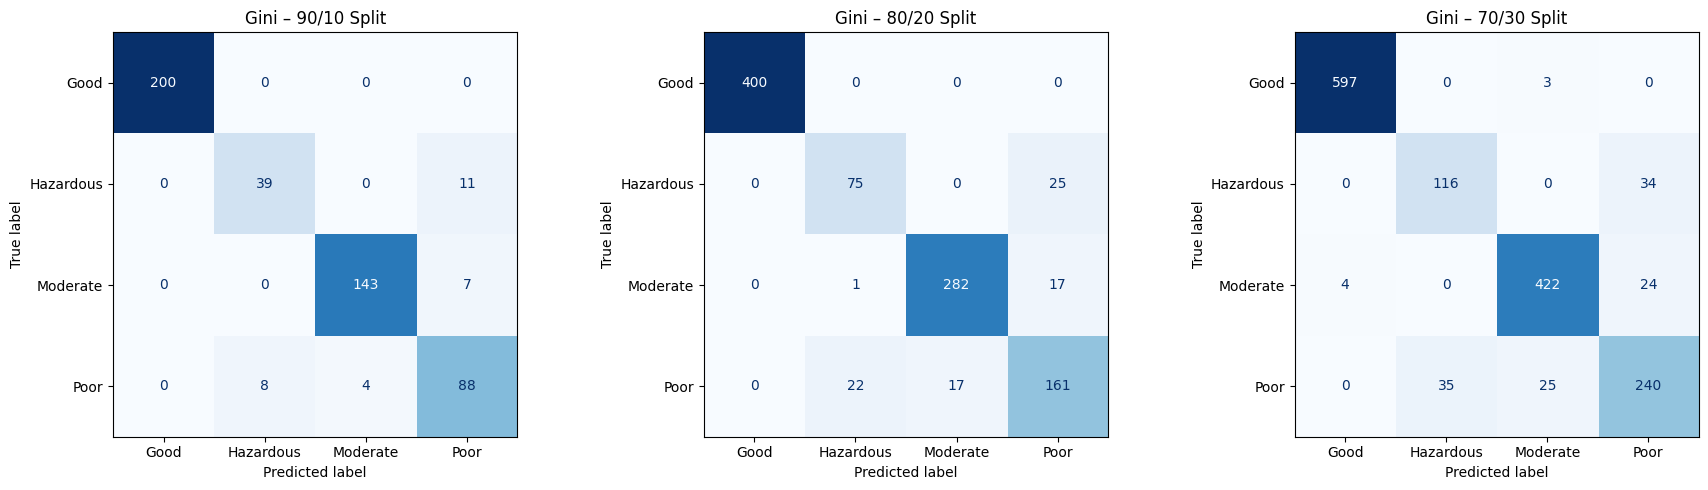

In [ ]:
gini_matrices = [gini_cm_90, gini_cm_80, gini_cm_70]
gini_models = [gini_model_90, gini_model_80, gini_model_70]
gini_splits = ["90/10", "80/20", "70/30"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, matrix, model, split in zip(axes, gini_matrices, gini_models, gini_splits):
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=model.classes_
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Gini – {split} Split")

plt.tight_layout()
plt.show()


#### Gini Accuracy Comparison


In [ ]:
gini_results = pd.DataFrame({
    "Train/Test Split": ["90/10", "80/20", "70/30"],
    "Accuracy (%)": [
        gini_accuracy_90 * 100,
        gini_accuracy_80 * 100,
        gini_accuracy_70 * 100
    ]
})

display(gini_results.round(2))

best_gini_split = gini_results.loc[gini_results["Accuracy (%)"].idxmax()]
print("Best Gini split:", best_gini_split["Train/Test Split"])
print(f"Best Gini accuracy: {best_gini_split['Accuracy (%)']:.2f}%")


,Train/Test Split,Accuracy (%)
0,90/10,94.00
1,80/20,91.80
2,70/30,91.67


Best Gini split: 90/10
Best Gini accuracy: 94.00%


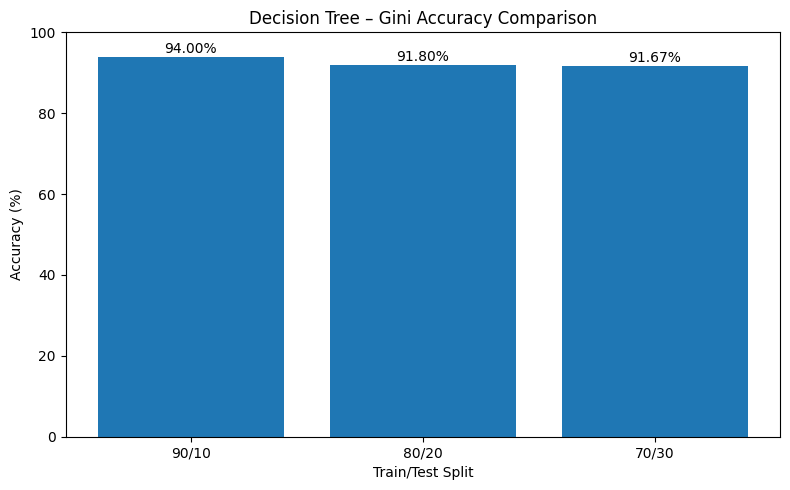

In [ ]:
plt.figure(figsize=(8, 5))
bars = plt.bar(
    gini_results["Train/Test Split"],
    gini_results["Accuracy (%)"]
)

plt.xlabel("Train/Test Split")
plt.ylabel("Accuracy (%)")
plt.title("Decision Tree – Gini Accuracy Comparison")
plt.ylim(0, 100)

for bar, value in zip(bars, gini_results["Accuracy (%)"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


#### Decision Tree Visualization – Gini (90/10)


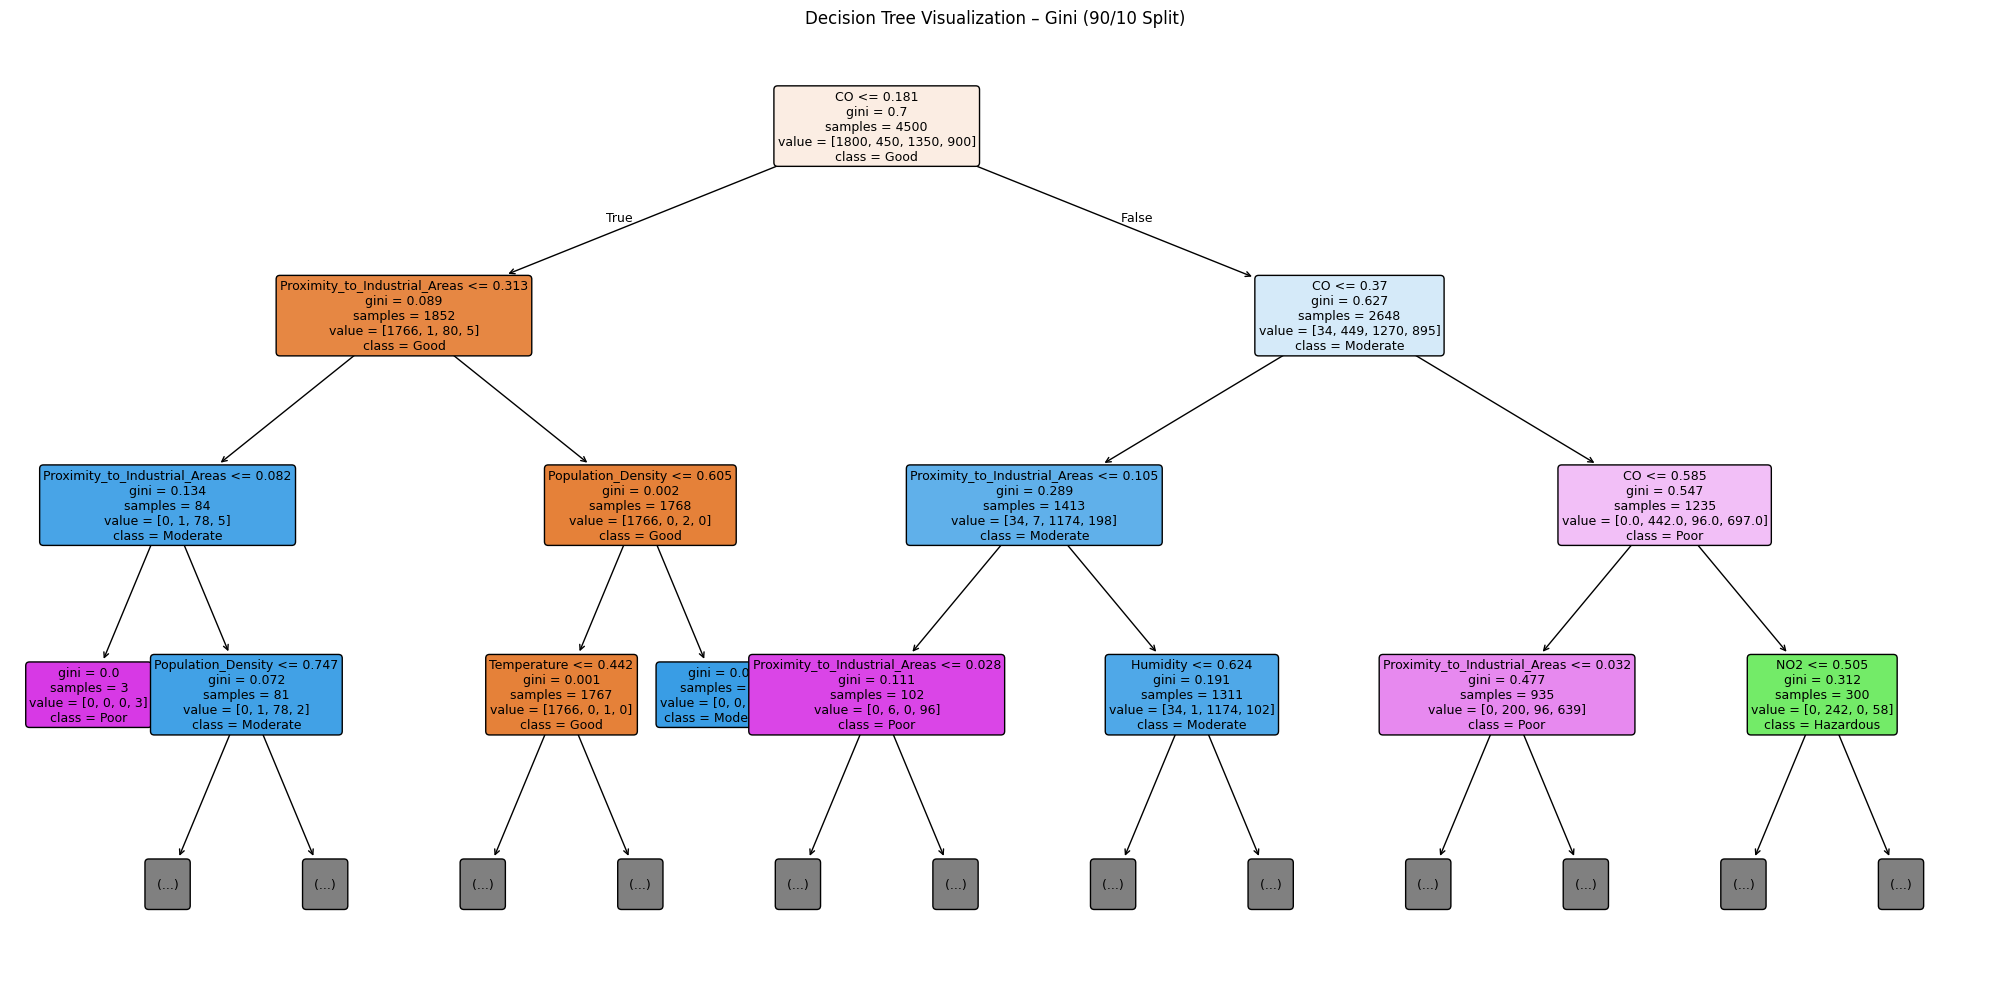

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    gini_model_90,
    feature_names=X_gini.columns,
    class_names=[str(label) for label in gini_model_90.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Visualization – Gini (90/10 Split)")
plt.tight_layout()
plt.show()


#### Gini Results Discussion

The Gini Decision Tree reached 94.00% (90/10), 91.80% (80/20) and 91.67% (70/30) accuracy, so the 90/10 partition gave the best Gini result. In all three confusion matrices the Good class is classified almost perfectly (200/200, 400/400 and 597/600 correct). Almost all errors occur between neighbouring severity levels: Moderate is confused with Hazardous (11, 25 and 34 cases), and Poor and Hazardous are confused with each other (e.g., 17 Poor and 17 Hazardous cases in the 80/20 split).

The tree for the 90/10 split starts with CO at the root (threshold ≈ 0.181), which shows that CO is the most informative attribute for separating the classes. Only the first three levels are drawn for readability; the full tree is deeper (depth 27), which suggests the model is fitted closely to the training data. The small gaps between the splits (about 2 percentage points) show that the result is fairly stable, but part of the 90/10 advantage may come from the particular 500 test records.


### Decision Tree Classification – Entropy (Information Gain)

This section applies the Decision Tree classification algorithm using the Entropy criterion (Information Gain) to predict Air Quality levels. Three different training and testing splits (90/10, 80/20, and 70/30) will be evaluated and compared using Accuracy and Confusion Matrices.

In [ ]:
from pathlib import Path
import pandas as pd

df = pd.read_csv("Preprocessed_dataset.csv" if Path("Preprocessed_dataset.csv").exists() else "Final_Preprocessed_Dataset.csv")

print(df.shape)
print(df.columns.tolist())
display(df.head())

(5000, 9)
['CO', 'NO2', 'Proximity_to_Industrial_Areas', 'Temperature', 'SO2', 'Population_Density', 'Humidity', 'PM10', 'Air Quality']


,CO,NO2,Proximity_to_Industrial_Areas,Temperature,SO2,Population_Density,Humidity,PM10,Air Quality
0,0.348534,0.200000,0.163090,0.362832,0.707606,0.170351,0.250814,0.512196,Moderate
1,0.322476,0.406957,0.150215,0.329646,0.715203,0.550065,0.429967,0.450651,Moderate
2,0.319218,0.295652,0.115880,0.214602,0.755264,0.560468,0.420195,0.617366,Moderate
3,0.162866,0.106087,0.369099,0.303097,0.638913,0.472042,0.033659,0.349876,Good
4,0.117264,0.252174,0.437768,0.289823,0.644912,0.149545,0.376764,0.494002,Good


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

X = df.drop(columns=["Air Quality"])
y = df["Air Quality"]

print("Features:", X.shape)
print("Target classes:", y.unique())

Features: (5000, 8)
Target classes: ['Moderate' 'Good' 'Hazardous' 'Poor']


In [ ]:
# Decision Tree - Entropy (90/10 Split)

X_train_90, X_test_10, y_train_90, y_test_10 = train_test_split(
    X, y, test_size=0.10, random_state=42, stratify=y
)

tree_entropy_90 = DecisionTreeClassifier(
    criterion="entropy", random_state=42
)

tree_entropy_90.fit(X_train_90, y_train_90)

y_pred_90 = tree_entropy_90.predict(X_test_10)

accuracy_90 = accuracy_score(y_test_10, y_pred_90)
cm_90 = confusion_matrix(y_test_10, y_pred_90)

print("Decision Tree - Entropy (90/10)")
print("Accuracy:", round(accuracy_90 * 100, 2), "%")
print("Confusion Matrix:")
print(cm_90)

Decision Tree - Entropy (90/10)
Accuracy: 92.2 %
Confusion Matrix:
[[199   0   1   0]
 [  0  36   0  14]
 [  0   0 141   9]
 [  0   9   6  85]]


In [ ]:
# Decision Tree - Entropy (80/20 Split)

X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

tree_entropy_80 = DecisionTreeClassifier(
    criterion="entropy", random_state=42
)

tree_entropy_80.fit(X_train_80, y_train_80)

y_pred_80 = tree_entropy_80.predict(X_test_20)

accuracy_80 = accuracy_score(y_test_20, y_pred_80)
cm_80 = confusion_matrix(y_test_20, y_pred_80)

print("Decision Tree - Entropy (80/20)")
print("Accuracy:", round(accuracy_80 * 100, 2), "%")
print("Confusion Matrix:")
print(cm_80)

Decision Tree - Entropy (80/20)
Accuracy: 92.0 %
Confusion Matrix:
[[400   0   0   0]
 [  0  79   0  21]
 [  2   0 276  22]
 [  0  20  15 165]]


In [ ]:
# Decision Tree - Entropy (70/30 Split)

X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

tree_entropy_70 = DecisionTreeClassifier(
    criterion="entropy", random_state=42
)

tree_entropy_70.fit(X_train_70, y_train_70)

y_pred_70 = tree_entropy_70.predict(X_test_30)

accuracy_70 = accuracy_score(y_test_30, y_pred_70)
cm_70 = confusion_matrix(y_test_30, y_pred_70)

print("Decision Tree - Entropy (70/30)")
print("Accuracy:", round(accuracy_70 * 100, 2), "%")
print("Confusion Matrix:")
print(cm_70)

Decision Tree - Entropy (70/30)
Accuracy: 92.87 %
Confusion Matrix:
[[597   0   3   0]
 [  0 122   0  28]
 [  2   0 428  20]
 [  0  30  24 246]]


In [ ]:
# Entropy Accuracy Comparison

results_entropy = pd.DataFrame({
    "Train/Test Split": ["90/10", "80/20", "70/30"],
    "Accuracy (%)": [
        accuracy_90 * 100,
        accuracy_80 * 100,
        accuracy_70 * 100
    ]
})

display(results_entropy.round(2))

best_split = results_entropy.loc[
    results_entropy["Accuracy (%)"].idxmax()
]

print("Best Split:", best_split["Train/Test Split"])
print("Best Accuracy:", round(best_split["Accuracy (%)"], 2), "%")

,Train/Test Split,Accuracy (%)
0,90/10,92.20
1,80/20,92.00
2,70/30,92.87


Best Split: 70/30
Best Accuracy: 92.87 %


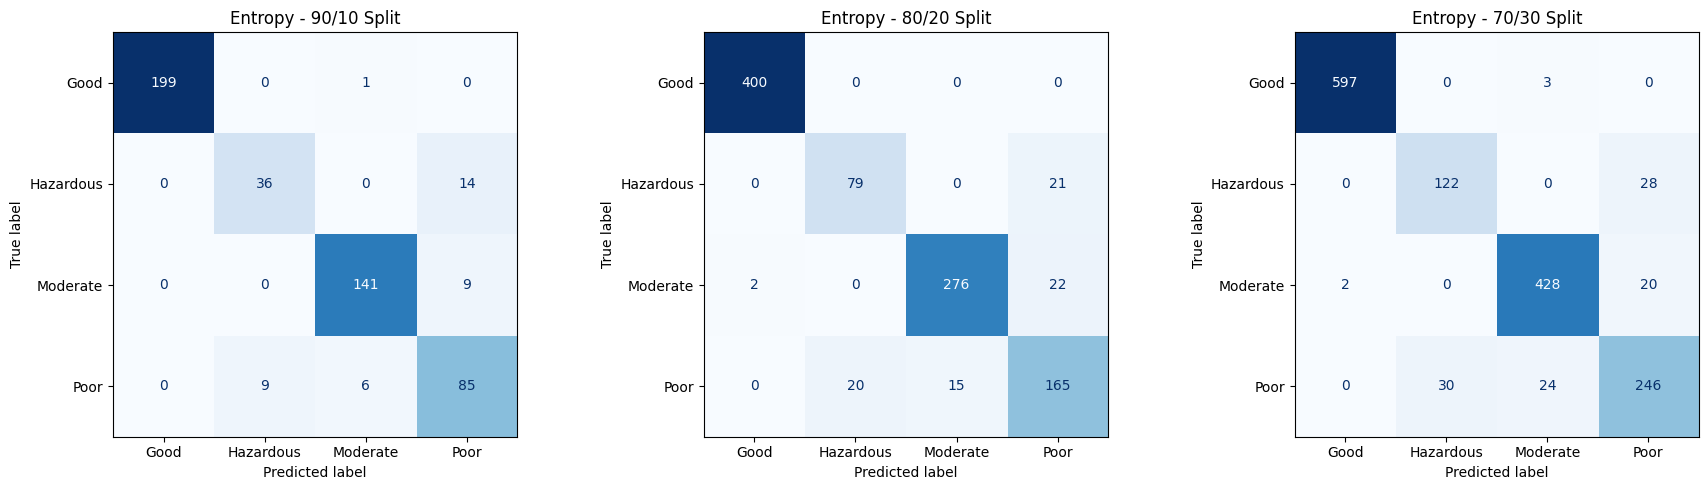

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

matrices = [cm_90, cm_80, cm_70]
splits = ["90/10", "80/20", "70/30"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i in range(3):
    ConfusionMatrixDisplay(
        confusion_matrix=matrices[i],
        display_labels=tree_entropy_90.classes_
    ).plot(ax=axes[i], cmap="Blues", colorbar=False)

    axes[i].set_title(
        f"Entropy - {splits[i]} Split"
    )

plt.tight_layout()
plt.show()

# Decision Tree – Entropy Tree Visualization (70/30)

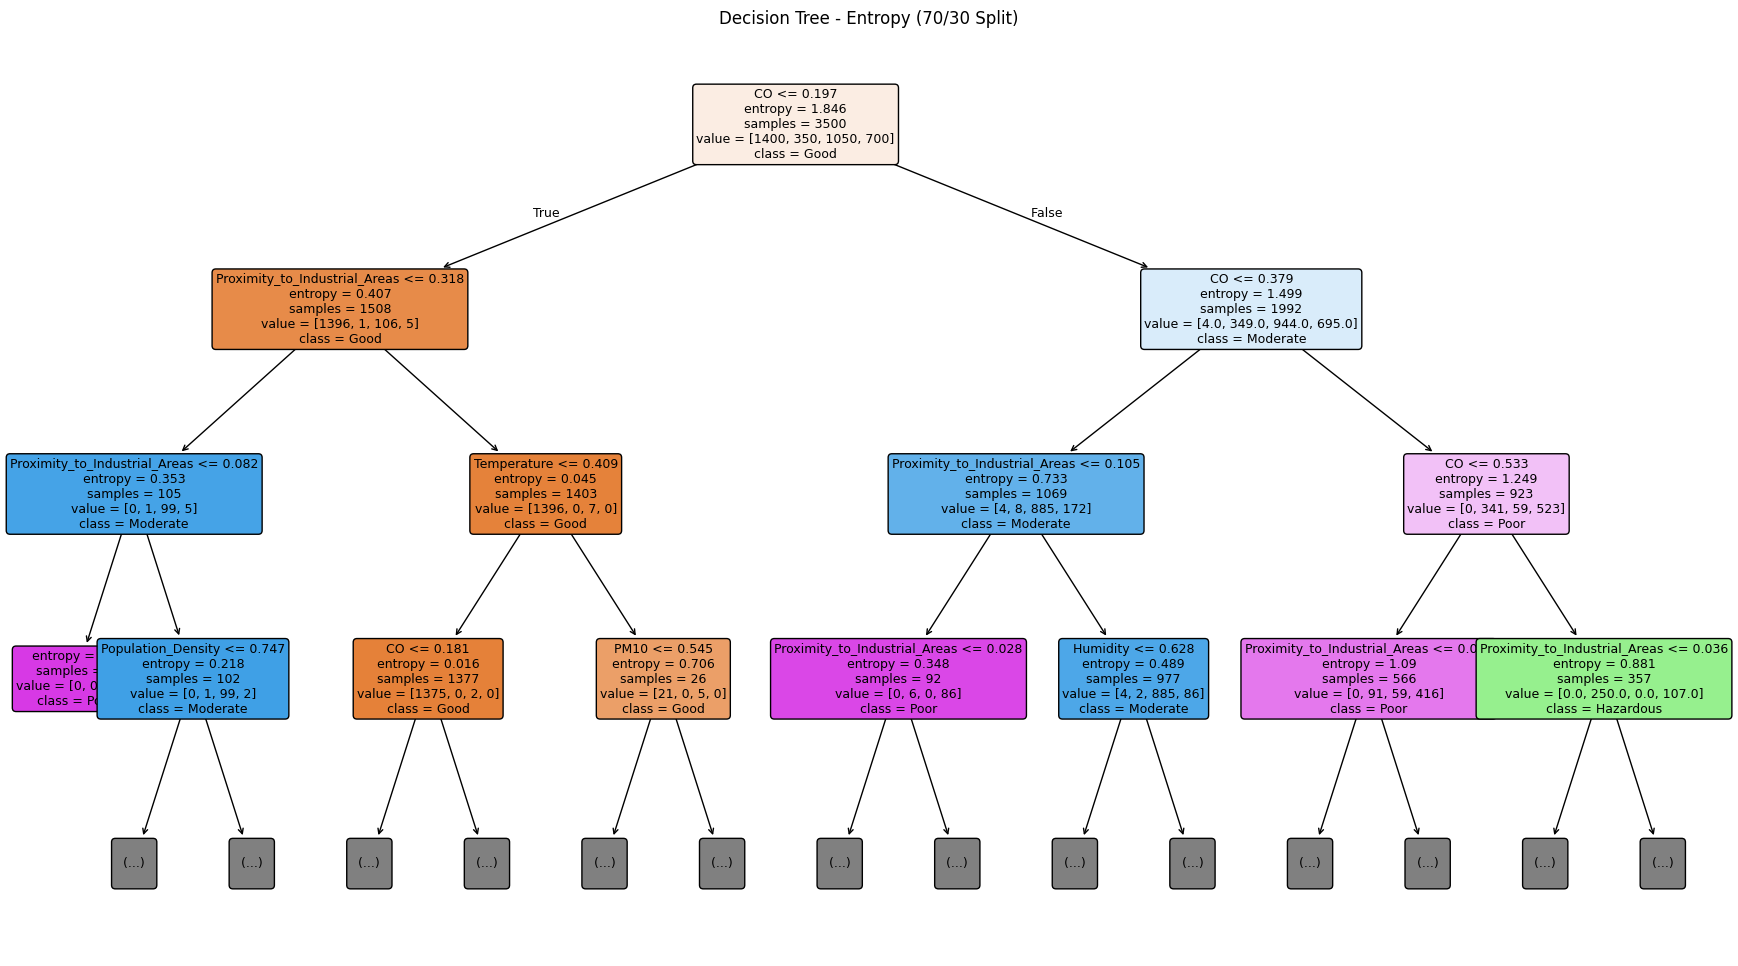

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(22, 12))

plot_tree(
    tree_entropy_70,
    feature_names=X.columns,
    class_names=tree_entropy_70.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree - Entropy (70/30 Split)")
plt.show()



The Decision Tree classifier was evaluated using three train/test splits: 90/10, 80/20, and 70/30. The accuracy scores were 92.20%, 92.00%, and 92.87%, respectively.

The 70/30 split achieved the highest accuracy (92.87%), making it the best-performing split among the three experiments. The confusion matrices show that most samples were classified correctly, with some misclassifications between the air quality categories.

The Decision Tree visualization shows that CO is the root feature, indicating its importance in the classification process. Other features, such as proximity to industrial areas and temperature, also contribute to predicting air quality levels.

Overall, the Entropy-based Decision Tree achieved consistent performance across the three data partitions, with accuracy above 92% in all experiments.

# Entropy Accuracy Comparison Visualization

This chart compares the accuracy scores of the Entropy-based Decision Tree across the three train/test splits (90/10, 80/20, and 70/30) to visually identify the best-performing partition.

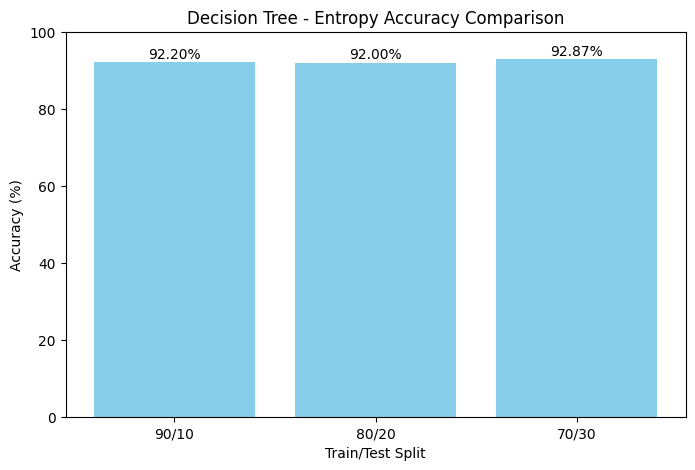

In [ ]:
# Entropy Accuracy Comparison Chart

import matplotlib.pyplot as plt

splits = ["90/10", "80/20", "70/30"]
accuracies = [
    accuracy_90 * 100,
    accuracy_80 * 100,
    accuracy_70 * 100
]

plt.figure(figsize=(8, 5))

bars = plt.bar(splits, accuracies, color="skyblue")

plt.xlabel("Train/Test Split")
plt.ylabel("Accuracy (%)")
plt.title("Decision Tree - Entropy Accuracy Comparison")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.show()

Entropy Accuracy Comparison – Discussion

The chart compares the accuracy of the Entropy-based Decision Tree using three different train/test splits. The 70/30 split achieved the highest accuracy (92.87%), followed by 90/10 (92.20%) and 80/20 (92.00%).

The differences between the three results are relatively small, indicating that the model maintained consistent classification performance across the tested partitions. Based on accuracy, the 70/30 split was selected as the best-performing configuration.

## Decision Tree Evaluation – Gini vs. Entropy

This section compares the two criteria on the same three train/test partitions. The table reports each accuracy, identifies the better criterion for each split, and summarizes the average accuracy for each criterion.


In [ ]:
criterion_comparison = pd.DataFrame({
    "Train/Test Split": ["90/10", "80/20", "70/30"],
    "Gini Accuracy (%)": [
        gini_accuracy_90 * 100,
        gini_accuracy_80 * 100,
        gini_accuracy_70 * 100
    ],
    "Entropy Accuracy (%)": [
        accuracy_90 * 100,
        accuracy_80 * 100,
        accuracy_70 * 100
    ]
})

def choose_criterion(row):
    if abs(row["Gini Accuracy (%)"] - row["Entropy Accuracy (%)"]) < 1e-9:
        return "Tie"
    return "Gini" if row["Gini Accuracy (%)"] > row["Entropy Accuracy (%)"] else "Entropy"

criterion_comparison["Best Criterion"] = criterion_comparison.apply(choose_criterion, axis=1)
display(criterion_comparison.round(2))

average_accuracy = pd.DataFrame({
    "Criterion": ["Gini", "Entropy"],
    "Average Accuracy (%)": [
        criterion_comparison["Gini Accuracy (%)"].mean(),
        criterion_comparison["Entropy Accuracy (%)"].mean()
    ]
})
display(average_accuracy.round(2))

best_average = average_accuracy.loc[average_accuracy["Average Accuracy (%)"].idxmax()]
print(
    f"Best criterion by average accuracy: {best_average['Criterion']} "
    f"({best_average['Average Accuracy (%)']:.2f}%)"
)

all_results = pd.DataFrame([
    ("Gini", "90/10", gini_accuracy_90 * 100),
    ("Gini", "80/20", gini_accuracy_80 * 100),
    ("Gini", "70/30", gini_accuracy_70 * 100),
    ("Entropy", "90/10", accuracy_90 * 100),
    ("Entropy", "80/20", accuracy_80 * 100),
    ("Entropy", "70/30", accuracy_70 * 100)
], columns=["Criterion", "Train/Test Split", "Accuracy (%)"])

best_configuration = all_results.loc[all_results["Accuracy (%)"].idxmax()]
print(
    "Best individual configuration: "
    f"{best_configuration['Criterion']} with "
    f"{best_configuration['Train/Test Split']} split "
    f"({best_configuration['Accuracy (%)']:.2f}%)"
)


,Train/Test Split,Gini Accuracy (%),Entropy Accuracy (%),Best Criterion
0,90/10,94.00,92.20,Gini
1,80/20,91.80,92.00,Entropy
2,70/30,91.67,92.87,Entropy


,Criterion,Average Accuracy (%)
0,Gini,92.49
1,Entropy,92.36


Best criterion by average accuracy: Gini (92.49%)
Best individual configuration: Gini with 90/10 split (94.00%)


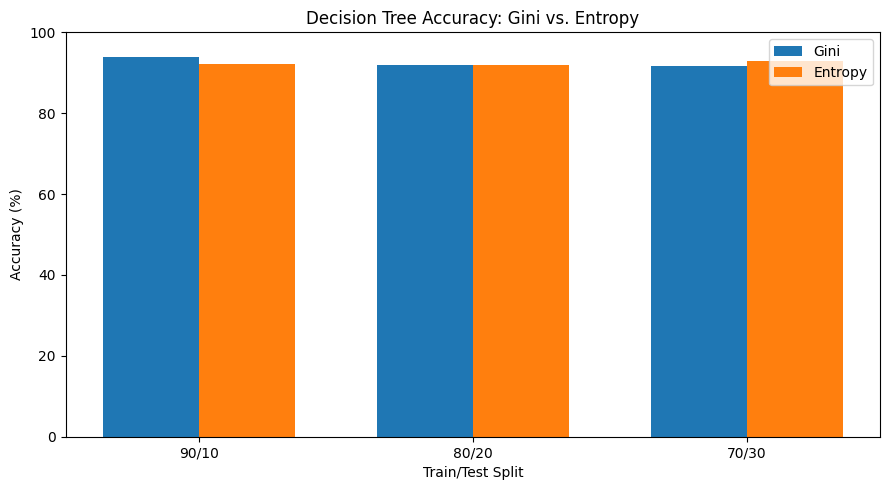

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

split_labels = criterion_comparison["Train/Test Split"]
x_positions = np.arange(len(split_labels))
bar_width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(
    x_positions - bar_width / 2,
    criterion_comparison["Gini Accuracy (%)"],
    bar_width,
    label="Gini"
)
plt.bar(
    x_positions + bar_width / 2,
    criterion_comparison["Entropy Accuracy (%)"],
    bar_width,
    label="Entropy"
)

plt.xticks(x_positions, split_labels)
plt.xlabel("Train/Test Split")
plt.ylabel("Accuracy (%)")
plt.title("Decision Tree Accuracy: Gini vs. Entropy")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()


### Comparison Discussion


The Decision Tree models using Gini and Entropy achieved similar average accuracy across the three train/test splits. Gini obtained an average accuracy of 92.49%, slightly higher than Entropy at 92.36%.

For the 90/10 split, Gini performed better, achieving 94.00% accuracy compared with 92.20% for Entropy. However, Entropy performed slightly better on the 80/20 split, with 92.00% accuracy compared with 91.80% for Gini. On the 70/30 split, Entropy achieved 92.87%, outperforming Gini at 91.67%.

Overall, Gini achieved the highest average accuracy, but the difference between the two criteria was small. Therefore, both criteria demonstrated comparable classification performance. The confusion matrices should also be considered to understand how well each model classified the different air quality categories


# 6. Evaluation and Comparison

This section consolidates the evaluation evidence produced by the experiments above. The six confusion matrices are displayed in the Gini and Entropy comparison figures in Section 5.2 (three matrices for each criterion). The accuracy comparison below places all six model configurations in one table.

For clustering, WCSS and Silhouette Score are reported together for K=2, K=3, and K=4. WCSS is expected to decrease as K increases, so it should be interpreted through the rate of reduction (the elbow pattern), rather than choosing the smallest WCSS value alone.

In [ ]:
# Consolidated evaluation tables for classification and clustering

classification_summary = pd.DataFrame([
    ["Gini", "90/10", gini_accuracy_90 * 100],
    ["Gini", "80/20", gini_accuracy_80 * 100],
    ["Gini", "70/30", gini_accuracy_70 * 100],
    ["Entropy", "90/10", accuracy_90 * 100],
    ["Entropy", "80/20", accuracy_80 * 100],
    ["Entropy", "70/30", accuracy_70 * 100],
], columns=["Criterion", "Train/Test Split", "Accuracy (%)"])

classification_summary["Accuracy (%)"] = classification_summary["Accuracy (%)"].round(2)
print("CLASSIFICATION: ALL SIX CONFIGURATIONS")
display(classification_summary)

clustering_summary = pd.DataFrame(kmeans_results)
clustering_summary = clustering_summary.rename(columns={
    "WCSS (Inertia)": "WCSS",
    "Silhouette Score": "Silhouette Score"
})
clustering_summary["WCSS"] = clustering_summary["WCSS"].round(2)
clustering_summary["Silhouette Score"] = clustering_summary["Silhouette Score"].round(4)
print("CLUSTERING: K-MEANS COMPARISON")
display(clustering_summary)

best_classification = classification_summary.loc[
    classification_summary["Accuracy (%)"].idxmax()
]
best_k_by_silhouette = int(
    clustering_summary.loc[clustering_summary["Silhouette Score"].idxmax(), "K"]
)

print(
    f"Best individual classifier: {best_classification['Criterion']} "
    f"with {best_classification['Train/Test Split']} "
    f"({best_classification['Accuracy (%)']:.2f}%)."
)
print(
    f"Best K by Silhouette Score: K={best_k_by_silhouette} "
    f"({clustering_summary['Silhouette Score'].max():.4f})."
)

CLASSIFICATION: ALL SIX CONFIGURATIONS


,Criterion,Train/Test Split,Accuracy (%)
0,Gini,90/10,94.00
1,Gini,80/20,91.80
2,Gini,70/30,91.67
3,Entropy,90/10,92.20
4,Entropy,80/20,92.00
5,Entropy,70/30,92.87


CLUSTERING: K-MEANS COMPARISON


,K,WCSS,Silhouette Score
0,2,22756.56,0.3495
1,3,18261.36,0.2705
2,4,17245.61,0.2195


Best individual classifier: Gini with 90/10 (94.00%).
Best K by Silhouette Score: K=2 (0.3495).


## 6.1 Evaluation Interpretation

The Gini Decision Tree achieved accuracies of 94.00%, 91.80%, and 91.67% for the 90/10, 80/20, and 70/30 splits, respectively. The Entropy Decision Tree achieved 92.20%, 92.00%, and 92.87%. Therefore, the highest individual classification result was Gini with the 90/10 split (94.00%). The average accuracies were approximately 92.49% for Gini and 92.36% for Entropy, indicating that the two criteria performed similarly overall.

For K-Means, K=2 achieved the highest Silhouette Score (0.3495), compared with 0.2705 for K=3 and 0.2195 for K=4. The K=2 solution also produced nearly balanced groups: 2,488 records (49.76%) and 2,512 records (50.24%). WCSS decreased from 22,756.56 at K=2 to 18,261.36 at K=3, then to 17,245.61 at K=4. The reduction was much smaller from K=3 to K=4 than from K=2 to K=3, suggesting diminishing returns when adding the fourth cluster.

Based on the strongest Silhouette Score and the balanced cluster sizes, K=2 is selected as the preferred solution in this analysis. The Elbow results provide supporting context but do not independently prove that K=2 is the only possible choice.

## 6.2 Choosing K

The three criteria do not point to the same K. The average Silhouette score is highest for K=2 (0.3495 vs 0.2705 and 0.2195). The WCSS curve shows its largest drop from K=2 to K=3 (22,756.56 → 18,261.36, about 20%) and a much smaller drop from K=3 to K=4 (→ 17,245.61, about 6%), so the elbow appears around K=3. K=4 matches the four Air Quality classes, but it has the lowest Silhouette score. Because the Silhouette score gives the clearest numerical separation, balanced clusters (49.8% / 50.2%) and an easy interpretation (a low-pollution group and a high-pollution group), K=2 is selected as the final choice. K=3 and K=4 give more detailed groups that follow the Good / Moderate / Poor-Hazardous pattern more closely, so they are useful when finer groups are needed.


# 7. Findings and Discussion

## 7.1 Main Classification Findings

The Decision Tree experiments show consistently high accuracy across the six configurations (91.67%–94.00%). Gini with the 90/10 split produced the highest individual accuracy (94.00%), while Entropy with the 70/30 split was the strongest Entropy configuration (92.87%). The average difference between Gini and Entropy is small, so the results do not indicate a large overall advantage for one splitting criterion.

The confusion matrices provide additional information about the classification performance of each Air Quality class. They help identify which classes were correctly classified and where misclassifications occurred. Therefore, accuracy should be considered alongside the confusion matrices to provide a more complete evaluation of the model.

## 7.2 Decision Tree Interpretation

The final Decision Tree visualizations for the best Entropy and Gini models are provided above. The Entropy tree represents the 70/30 split, while the Gini tree represents the 90/10 split, as these models achieved the highest accuracy for each selection measure.

In the displayed Entropy tree, CO appears at the root, indicating that it is the first feature used by that fitted tree to divide the observations. Other features are used in subsequent branches. A tree split indicates a useful decision rule within this fitted model; it does not establish that a feature causes a change in air quality.

The Gini Decision Tree visualization represents the model trained using the 90/10 split, which achieved the highest Gini accuracy of 94.00%. Similar to the Entropy tree, the root node shows the first feature selected by the model to divide the data. The branches represent the decision rules used to classify observations into different Air Quality categories.

The feature importance results below provide a complementary model-based summary. These values should be interpreted as importance within the fitted Gini Decision Tree, not as causal effects.

The Gini feature importance results show that CO is the most influential feature in the model, with an importance value of 0.6742 (67.42%). Proximity_to_Industrial_Areas is the second most important feature, with an importance value of 0.1526 (15.26%). The remaining features have smaller contributions: NO2 (3.88%), SO2 (3.31%), Temperature (3.19%), Population_Density (3.03%), Humidity (2.47%), and PM10 (1.44%).

These results indicate that the Gini Decision Tree relies mainly on CO when making Air Quality predictions, followed by proximity to industrial areas. The importance values represent each feature's contribution to the decisions made by this fitted model. However, they do not mean that CO directly causes changes in air quality.

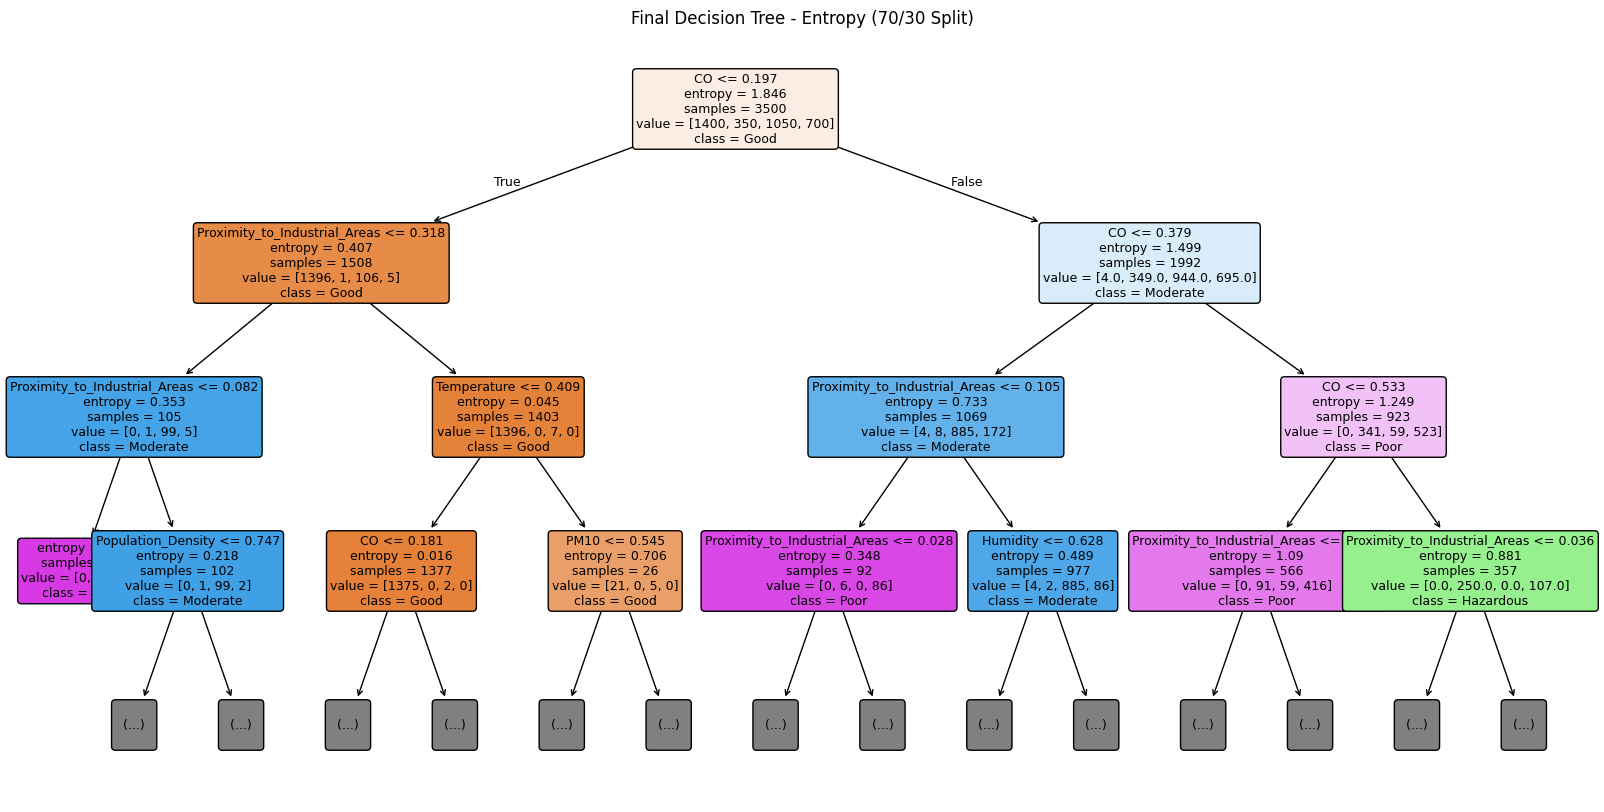

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    tree_entropy_70,
    feature_names=X.columns,
    class_names=tree_entropy_70.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Final Decision Tree - Entropy (70/30 Split)")
plt.show()

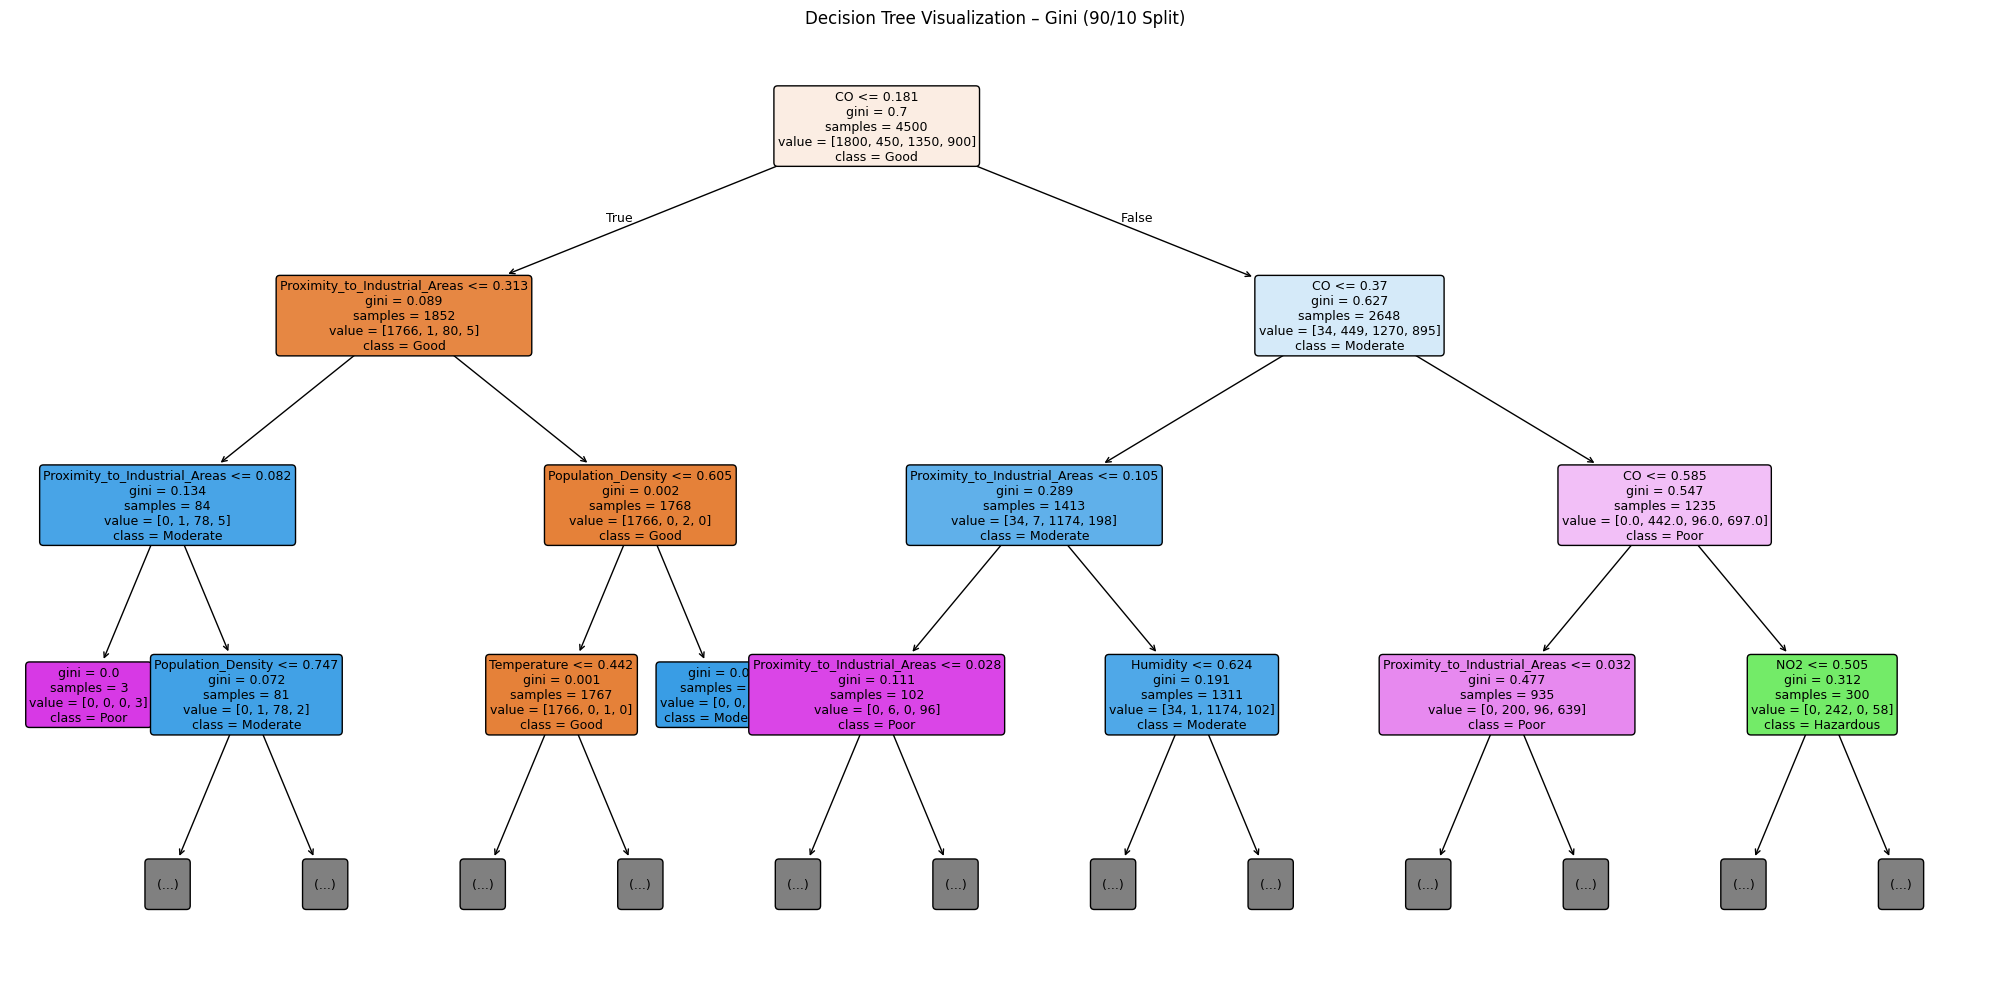

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    gini_model_90,
    feature_names=X_gini.columns,
    class_names=[str(label) for label in gini_model_90.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Visualization – Gini (90/10 Split)")
plt.tight_layout()
plt.show()


,Feature,Importance
0,CO,0.674183
2,Proximity_to_Industrial_Areas,0.152620
1,NO2,0.038836
4,SO2,0.033070
3,Temperature,0.031888
5,Population_Density,0.030296
6,Humidity,0.024689
7,PM10,0.014418


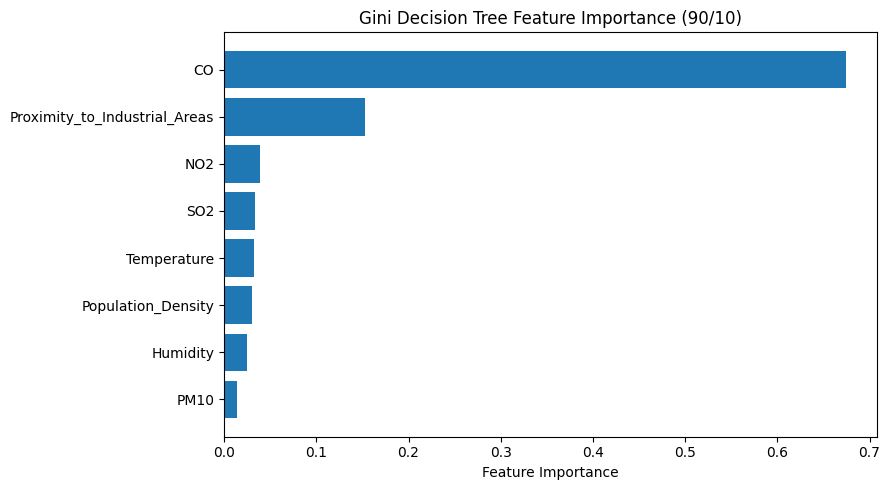

In [ ]:
# Feature importance from the best individual Gini configuration (90/10)

feature_importance = pd.DataFrame({
    "Feature": X_gini.columns,
    "Importance": gini_model_90.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance.round(6))

plt.figure(figsize=(9, 5))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Gini Decision Tree Feature Importance (90/10)")
plt.tight_layout()
plt.show()

## 7.3 K-Means Cluster Interpretation



In [ ]:
# Feature profiles and post-hoc Air Quality distribution for each K

cluster_features = df_cluster.columns.tolist()

for k in [2, 3, 4]:
    print(f"\nFEATURE MEANS BY CLUSTER — K={k}")
    profile = df[cluster_features].copy()
    profile["Cluster"] = cluster_labels[k]
    display(profile.groupby("Cluster")[cluster_features].mean().round(3))

    print(f"AIR QUALITY DISTRIBUTION WITHIN CLUSTERS — K={k}")
    # Air Quality is used here only to describe the clusters after fitting.
    # It was excluded from X_scaled and was not used by K-Means.
    quality_profile = pd.crosstab(
        pd.Series(cluster_labels[k], name="Cluster"),
        df["Air Quality"],
        normalize="index"
    ) * 100
    display(quality_profile.round(1))


FEATURE MEANS BY CLUSTER — K=2


,CO,NO2,Proximity_to_Industrial_Areas,Temperature,SO2,Population_Density,Humidity,PM10
Cluster,,,,,,,,
0,0.411,0.434,0.137,0.464,0.765,0.519,0.469,0.626
1,0.145,0.228,0.370,0.273,0.640,0.287,0.272,0.470


AIR QUALITY DISTRIBUTION WITHIN CLUSTERS — K=2


Air Quality,Good,Hazardous,Moderate,Poor
Cluster,,,,
0,0.0,20.1,39.8,40.1
1,79.6,0.0,20.3,0.1



FEATURE MEANS BY CLUSTER — K=3


,CO,NO2,Proximity_to_Industrial_Areas,Temperature,SO2,Population_Density,Humidity,PM10
Cluster,,,,,,,,
0,0.302,0.345,0.175,0.380,0.719,0.419,0.384,0.577
1,0.518,0.517,0.107,0.545,0.805,0.602,0.539,0.664
2,0.119,0.213,0.405,0.257,0.630,0.275,0.261,0.457


... (2 outputs left out)


FEATURE MEANS BY CLUSTER — K=4


,CO,NO2,Proximity_to_Industrial_Areas,Temperature,SO2,Population_Density,Humidity,PM10
Cluster,,,,,,,,
0,0.117,0.211,0.406,0.257,0.630,0.274,0.261,0.456
1,0.586,0.583,0.095,0.614,0.824,0.664,0.578,0.690
2,0.285,0.332,0.185,0.370,0.710,0.399,0.367,0.566
3,0.433,0.441,0.125,0.462,0.778,0.534,0.489,0.635


AIR QUALITY DISTRIBUTION WITHIN CLUSTERS — K=4


Air Quality,Good,Hazardous,Moderate,Poor
Cluster,,,,
0,97.6,0.0,2.4,0.0
1,0.0,79.6,0.0,20.4
2,0.5,0.0,91.6,7.9
3,0.0,7.3,11.6,81.0




K-Means was applied using the eight numerical features related to air quality and pollution. The Air Quality target was not used during model training.

PCA was used to visualize the clusters in two dimensions. The first two principal components explain 67.31% of the total variance (PC1: 59.61% and PC2: 7.70%).

The results were examined using three values of K: 2, 3, and 4. The feature means in the tables were calculated from the Min-Max normalized dataset, so their values range from 0 to 1. StandardScaler was applied separately to the numerical features before training K-Means. Air Quality labels were used only after clustering to describe the distribution of Good, Moderate, Poor, and Hazardous observations in each cluster.

K=2

When K=2, the data was divided into two clusters.

Cluster 0 has higher average values for CO (0.411), NO2 (0.434), SO2 (0.765), and PM10 (0.626). Its observations are mainly Poor (40.1%) and Moderate (39.8%), while 20.1% are Hazardous.

Cluster 1 mainly contains Good observations (79.6%), followed by Moderate observations (20.3%) and a small percentage of Poor observations (0.1%).

This result shows a noticeable difference between the two clusters in terms of their Air Quality distributions and average pollution indicators. Cluster 0 has higher averages for several pollution indicators, while Cluster 1 mainly contains observations with Good Air Quality.

K=3

When K=3, the data was divided into three clusters with different Air Quality patterns.

Cluster 1 has the highest average values for several pollution indicators, including CO (0.518), NO2 (0.517), SO2 (0.805), and PM10 (0.664). It contains 57.2% Poor observations and 42.4% Hazardous observations.

Cluster 0 mainly contains Moderate observations (80.8%), while Cluster 2 mainly contains Good observations (96.5%).

Compared to K=2, this result provides more detail about the different Air Quality groups in the dataset.

K=4

When K=4, the data was divided into four clusters, providing more detailed results.

Cluster 0 mainly contains Good observations (97.6%) and has the lowest average CO (0.117) and NO2 (0.211) values.

Cluster 1 mainly contains Hazardous observations (79.6%), followed by Poor observations (20.4%). It also has the highest average values for several pollution indicators, including CO (0.586), NO2 (0.583), SO2 (0.824), and PM10 (0.690).

Cluster 2 mainly contains Moderate observations (91.6%), with 7.9% Poor observations.

Cluster 3 mainly contains Poor observations (81.0%), followed by Moderate observations (11.6%) and Hazardous observations (7.3%).

These results show that K=4 separates the observations into more specific groups, with each cluster having a dominant Air Quality category.

Overall Comparison

The three K values produced different clustering results:

K=2: Achieved the highest Silhouette Score (0.3495) and produced two nearly balanced clusters. Its WCSS was 22,756.56.

K=3: Achieved a Silhouette Score of 0.2705 and provided more detail about the distribution of Air Quality categories. Its WCSS was 18,261.36.

K=4: Achieved a Silhouette Score of 0.2195 and provided the most detailed separation, with each cluster having a dominant Air Quality category. Its WCSS was 17,245.61.

Based on the Silhouette Scores, K=2 was selected as the best clustering result among the tested values. It achieved the highest Silhouette Score and produced two nearly balanced clusters. However, K=3 and K=4 were also examined because they provide additional information about the differences in air pollution features and Air Quality categories.

Overall, K-Means helped identify groups of observations with different air pollution characteristics and Air Quality levels.

## 7.4 Comparison with a Published Research Study

Rahman et al. (2024) presented AirNet: Predictive Machine Learning Model for Air Quality Forecasting Using Web Interface in Environmental Systems Research. Their study used a different air-pollution dataset containing 23,463 instances and 12 features before preprocessing, and evaluated several classification algorithms. The authors reported 100% accuracy for both Random Forest and Decision Tree in their experimental results [2].

In this project, the best individual Decision Tree result was 94.00% using the Gini criterion with a 90/10 train-test split. Although the accuracy reported in the AirNet study is higher, the two results should not be treated as a direct model-to-model comparison because the datasets, target categories, feature sets, preprocessing methods, and experimental settings differ. This comparison provides context showing that Decision Trees have been applied successfully to air-quality classification, while the results of the current project are specific to its 5,000-record dataset and evaluation design.

## 7.5 Overall Findings and Limitations

The classification results indicate that the selected environmental measurements contain useful information for classifying the dataset's Air Quality categories. CO was an important feature in the fitted Decision Tree, appearing as the root splitting feature in some experiments. The Gini and Entropy criteria achieved similar average accuracy, with Gini obtaining a slightly higher average accuracy of 92.49%, compared with 92.36% for Entropy. The highest individual accuracy was 94.00%, achieved by Gini using the 90/10 train-test split.

For clustering, K=2 achieved the highest Silhouette Score of 0.3495 among the tested values, making it the preferred choice based on this metric. However, the score indicates moderate cluster separation rather than strongly separated clusters. The WCSS curve shows diminishing reductions as the number of clusters increases, so the elbow evidence should be considered together with the Silhouette results rather than as a standalone decision.

The analysis has several limitations. The dataset represents a fixed collection of records rather than live monitoring data. Decision Tree accuracy may depend on the particular train/test partition and dataset characteristics. K-Means is sensitive to scaling, outliers, and the selected K value. PCA shows only two dimensions and therefore does not preserve all the information in the original feature space. Finally, cluster membership describes similarity in the selected measurements and does not establish causation or replace the original Air Quality labels.

## 8. References

[1] M. Mateen, “Air Quality and Pollution Assessment,” Kaggle. [Online]. Available: https://www.kaggle.com/datasets/mujtabamatin/air-quality-and-pollution-assessment

[2] M. M. Rahman et al., “AirNet: Predictive Machine Learning Model for Air Quality Forecasting Using Web Interface,” Environmental Systems Research, vol. 13, Art. no. 44, 2024, doi: 10.1186/s40068-024-00378-z.